**Metodo BRIEF**\
Grupo 04\
Integrantes:
* Flores Baldoceda, Andres Francisco    20257600E
* Lazo Pampa, Victor Raul               20257639I
* Lopez Mendoza, Ruben                  20257664C
* Quispe Huanca, Juan Christian         20257661D

Paper: 
* "BRIEF: Binary Robust Independent Elementary Features" \
URL: https://link.springer.com/chapter/10.1007/978-3-642-15561-1_56

Data: 
* Trees (Blur), Graffiti (Viewpoint), Wall (Viewpoint), Ubc (JPEG Compression), Leuven (Light) \
https://www.robots.ox.ac.uk/~vgg/research/affine/

* Fountain (Viewpoint)
**PFL CVLAB Multi-View Dataset** (de Strecha et al.) \
https://github.com/openMVG/SfM_quality_evaluation/tree/348a981ef51112e9848acfb20004f4ed6fbc6ce3/Benchmarking_Camera_Calibration_2008/fountain-P11



Librerias

In [2]:
%pip install numpy
# %conda install numpy -y
# %pip install --user numpy
%pip install opencv-python
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
# import cv2
import matplotlib.pyplot as plt

np.random.seed(42)  # Para reproducibilidad de resultados

from src.sampling import generate_brief_pairs
from src.descriptor import BRIEFExtractor
from src.matcher import (
    evaluar_reconocimiento_general,
    cargar_puntos_con_homografia,
    get_base_dir,
    hamming_distance
)

Calculando tasas de reconocimiento...


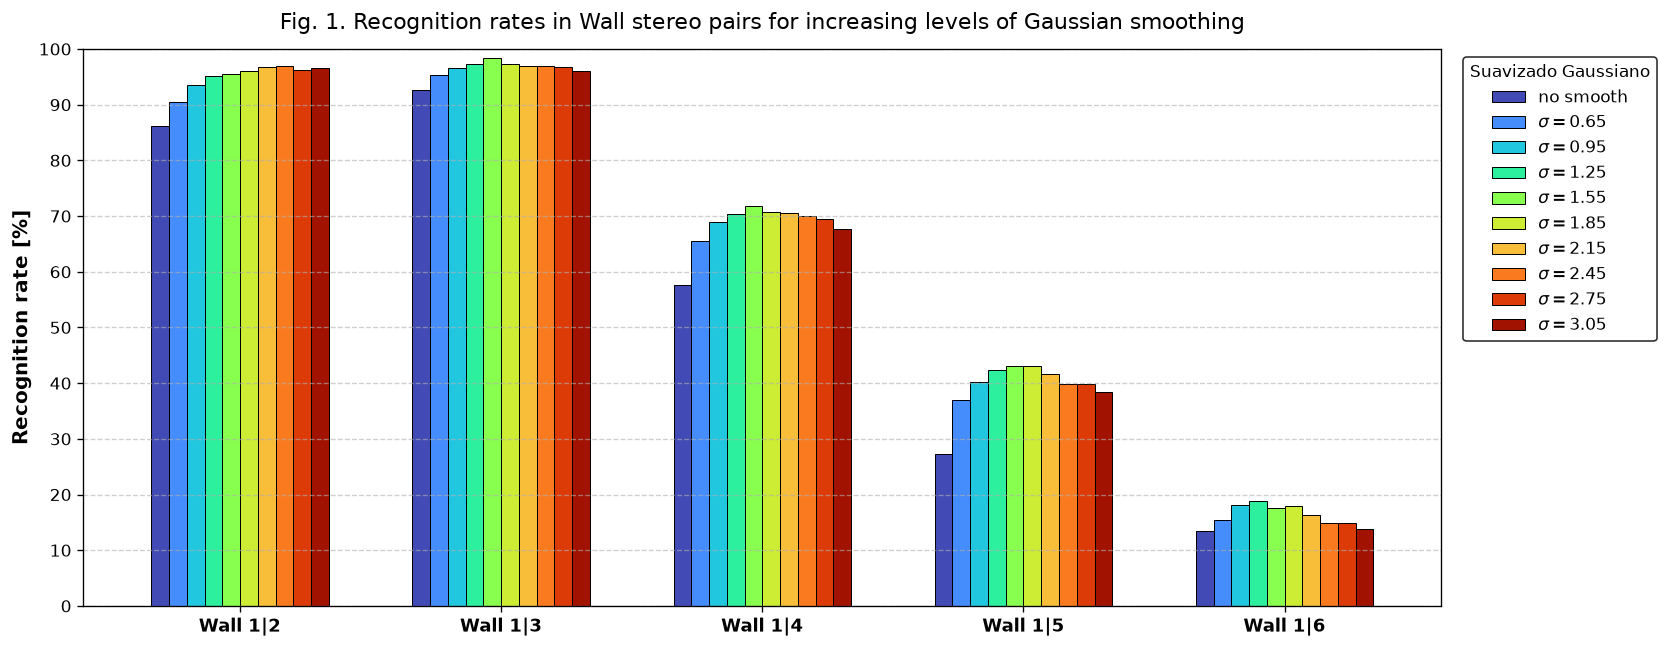

In [4]:
# 1. Configuración de parámetros
dataset = get_base_dir("Wall")
sigmas = [0, 0.65, 0.95, 1.25, 1.55, 1.85, 2.15, 2.45, 2.75, 3.05]
etiquetas_sigma = ['no smooth', '0.65', '0.95', '1.25', '1.55', '1.85', '2.15', '2.45', '2.75', '3.05']

n_pares = 512
pairs_G2 = generate_brief_pairs(patch_size=31, num_pairs=n_pares, strategy='G_II')

# 2. Cálculo de tasas de reconocimiento
tasas_fig1 = []
print("Calculando tasas de reconocimiento...")
for s in sigmas:
    extractor = BRIEFExtractor(patch_size=31, num_pairs=n_pares, strategy='G_II', sigma=s, pairs=pairs_G2)
    tasas_par, nombres_pares = evaluar_reconocimiento_general(dataset, extractor, num_puntos=1000)
    tasas_fig1.append(tasas_par)

tasas_matriz = np.array(tasas_fig1).T

# ==============================================================================
# 3. Gráfico usando colormap nativo de Matplotlib
# ==============================================================================
fig, ax = plt.subplots(figsize=(14, 5.5), dpi = 120)

num_pares = len(nombres_pares)
num_sigmas = len(sigmas)
x = np.arange(num_pares)

ancho_grupo = 0.68
ancho_barra = ancho_grupo/num_sigmas

# Usamos 'turbo' nativo de matplotlib (el mapa de colores que mejor se parece a la Figura 1)
# Alternativa: puedes cambiar 'turbo' por 'jet' si prefieres el colormap clásico
colores = plt.cm.turbo(np.linspace(0.08, 0.95, num_sigmas))

for j in range(num_sigmas):
    offset = (j - num_sigmas / 2 + 0.5) * ancho_barra
    ax.bar(x + offset, tasas_matriz[:, j], width=ancho_barra, 
           label=('no smooth' if j == 0 else r'$\sigma = $' + etiquetas_sigma[j]), color=colores[j],
           edgecolor='black', linewidth=0.6)

ax.set_ylabel('Recognition rate [%]', fontsize=12, fontweight='bold')
ax.set_title('Fig. 1. Recognition rates in Wall stereo pairs for increasing levels of Gaussian smoothing', fontsize=13, pad=12)
ax.set_xticks(x)
ax.set_xticklabels(nombres_pares, fontsize=11, fontweight='bold')

# Escala de 0 a 100 de 10 en 10
ax.set_ylim(0, 100)
ax.set_yticks(np.arange(0, 101, 10))
ax.set_xlim(-0.6, num_pares - 0.4)

ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.legend(title='Suavizado Gaussiano', bbox_to_anchor=(1.01, 1), loc='upper left', frameon=True, edgecolor='black')
plt.tight_layout()
plt.show()

In [5]:
print("NOMBRES DE PARES:", nombres_pares)
print("MATRIZ DE TASAS CALCULADAS:")
print(np.round(tasas_matriz, 1))

NOMBRES DE PARES: ['Wall 1|2', 'Wall 1|3', 'Wall 1|4', 'Wall 1|5', 'Wall 1|6']
MATRIZ DE TASAS CALCULADAS:
[[86.2 90.4 93.6 95.2 95.6 96.1 96.7 96.9 96.2 96.6]
 [92.6 95.3 96.6 97.3 98.3 97.3 96.9 97.  96.7 96.1]
 [57.6 65.6 69.  70.4 71.8 70.7 70.6 70.1 69.4 67.6]
 [27.3 37.  40.2 42.4 43.  43.  41.6 39.8 39.8 38.5]
 [13.5 15.5 18.2 18.8 17.5 17.9 16.3 14.9 14.9 13.9]]


Figura 2

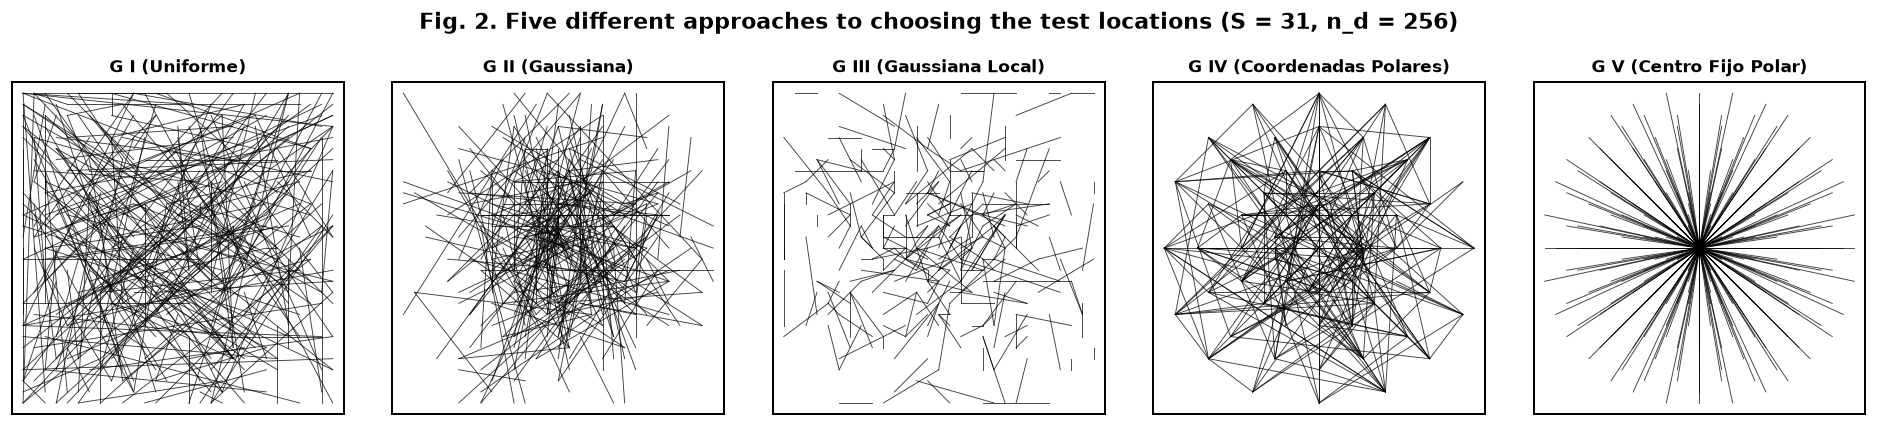

In [6]:
# ==============================================================================
# FIGURA 2: Los 5 enfoques de muestreo espacial (G_I a G_V)
# ==============================================================================
estrategias = ['G_I', 'G_II', 'G_III', 'G_IV', 'G_V']
titulos = ['G I (Uniforme)', 'G II (Gaussiana)', 'G III (Gaussiana Local)', 'G IV (Coordenadas Polares)', 'G V (Centro Fijo Polar)']
S = 31
mitad = S // 2

fig, axes = plt.subplots(1, 5, figsize=(16, 3.4), dpi=120)
np.random.seed(42)

for ax, est, titulo in zip(axes, estrategias, titulos):
    X, Y = generate_brief_pairs(patch_size=S, num_pairs=256, strategy=est)
    for (x1, y1), (x2, y2) in zip(X, Y):
        ax.plot([x1, x2], [y1, y2], color='black', linewidth=0.55, alpha=0.75)
    ax.set_xlim(-mitad, mitad)
    ax.set_ylim(-mitad, mitad)
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(titulo, fontsize=10, fontweight='bold')
    for spine in ax.spines.values():
        spine.set_linewidth(1.2)

fig.suptitle('Fig. 2. Five different approaches to choosing the test locations (S = 31, n_d = 256)', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


Figura 3

Calculando tasas de reconocimiento para las 5 geometrías (G_I a G_V)...


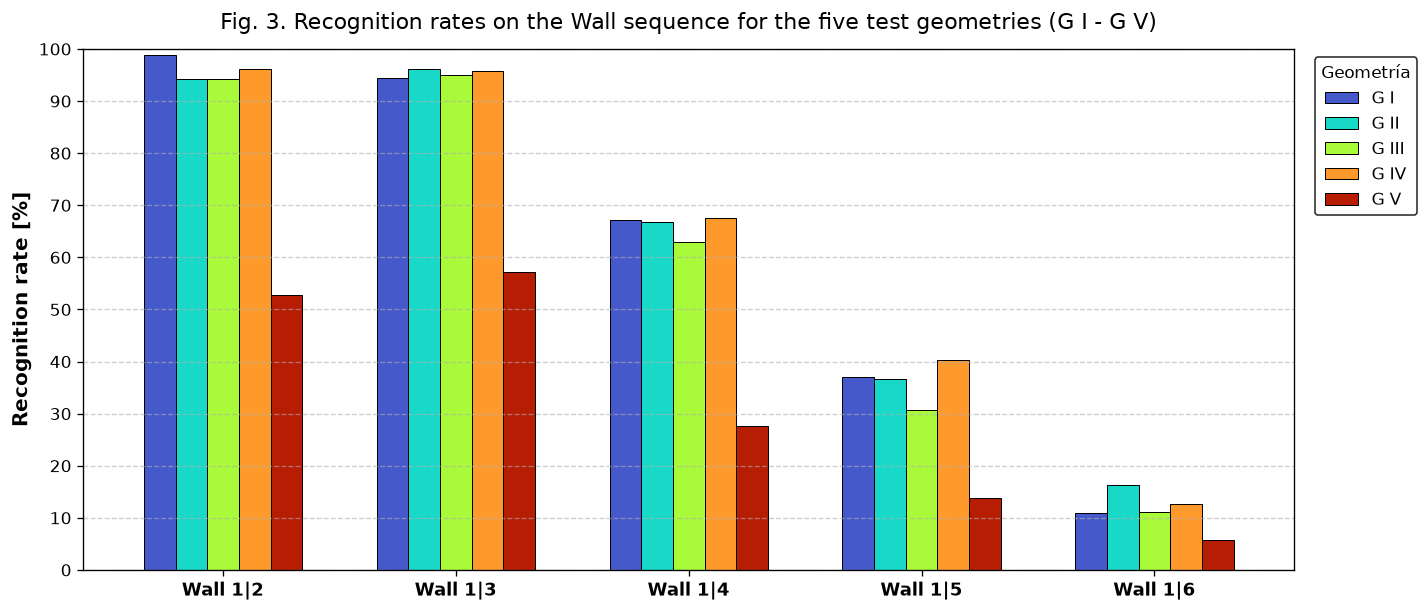

MATRIZ DE TASAS (FIGURA 3 - Filas: Wall 1|2..1|6, Columnas: G_I..G_V):
[[98.8 94.3 94.3 96.1 52.8]
 [94.5 96.1 95.  95.7 57.1]
 [67.1 66.7 62.9 67.6 27.7]
 [37.  36.7 30.7 40.3 13.8]
 [11.  16.3 11.1 12.7  5.7]]


In [7]:
# ==============================================================================
# FIGURA 3: Tasas de reconocimiento para las 5 geometrías (G_I a G_V)
# ==============================================================================
dataset = get_base_dir("Wall")
estrategias = ['G_I', 'G_II', 'G_III', 'G_IV', 'G_V']
etiquetas_geo = ['G I', 'G II', 'G III', 'G IV', 'G V']
n_pares_fig3 = 256
sigma_fig3 = 2.0

np.random.seed(42)
tasas_fig3 = []
print("Calculando tasas de reconocimiento para las 5 geometrías (G_I a G_V)...")
for est in estrategias:
    pares_est = generate_brief_pairs(patch_size=31, num_pairs=n_pares_fig3, strategy=est)
    extractor = BRIEFExtractor(patch_size=31, num_pairs=n_pares_fig3, strategy=est, sigma=sigma_fig3, pairs=pares_est)
    tasas_par, nombres_pares = evaluar_reconocimiento_general(dataset, extractor, num_puntos=1000)
    tasas_fig3.append(tasas_par)

tasas_matriz_fig3 = np.array(tasas_fig3).T  # Dimensiones: (5 pares de imágenes, 5 geometrías)

# Gráfico de barras agrupadas estilo Figura 3 del paper
fig, ax = plt.subplots(figsize=(12, 5.2), dpi=120)

num_imgs = len(nombres_pares)
num_geos = len(estrategias)
x = np.arange(num_imgs)

ancho_grupo = 0.68
ancho_barra = ancho_grupo / num_geos
colores_geo = plt.cm.turbo(np.linspace(0.10, 0.92, num_geos))

for j in range(num_geos):
    offset = (j - num_geos / 2 + 0.5) * ancho_barra
    ax.bar(
        x + offset,
        tasas_matriz_fig3[:, j],
        width=ancho_barra,
        label=etiquetas_geo[j],
        color=colores_geo[j],
        edgecolor='black',
        linewidth=0.6
    )

ax.set_ylabel('Recognition rate [%]', fontsize=12, fontweight='bold')
ax.set_title('Fig. 3. Recognition rates on the Wall sequence for the five test geometries (G I - G V)', fontsize=13, pad=12)
ax.set_xticks(x)
ax.set_xticklabels(nombres_pares, fontsize=11, fontweight='bold')
ax.set_ylim(0, 100)
ax.set_yticks(np.arange(0, 101, 10))
ax.set_xlim(-0.6, num_imgs - 0.4)

ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.legend(title='Geometría', bbox_to_anchor=(1.01, 1), loc='upper left', frameon=True, edgecolor='black')
plt.tight_layout()
plt.show()

print("MATRIZ DE TASAS (FIGURA 3 - Filas: Wall 1|2..1|6, Columnas: G_I..G_V):")
print(np.round(tasas_matriz_fig3, 1))


Extrayendo ~4000 puntos y calculando distribuciones de distancia de Hamming...


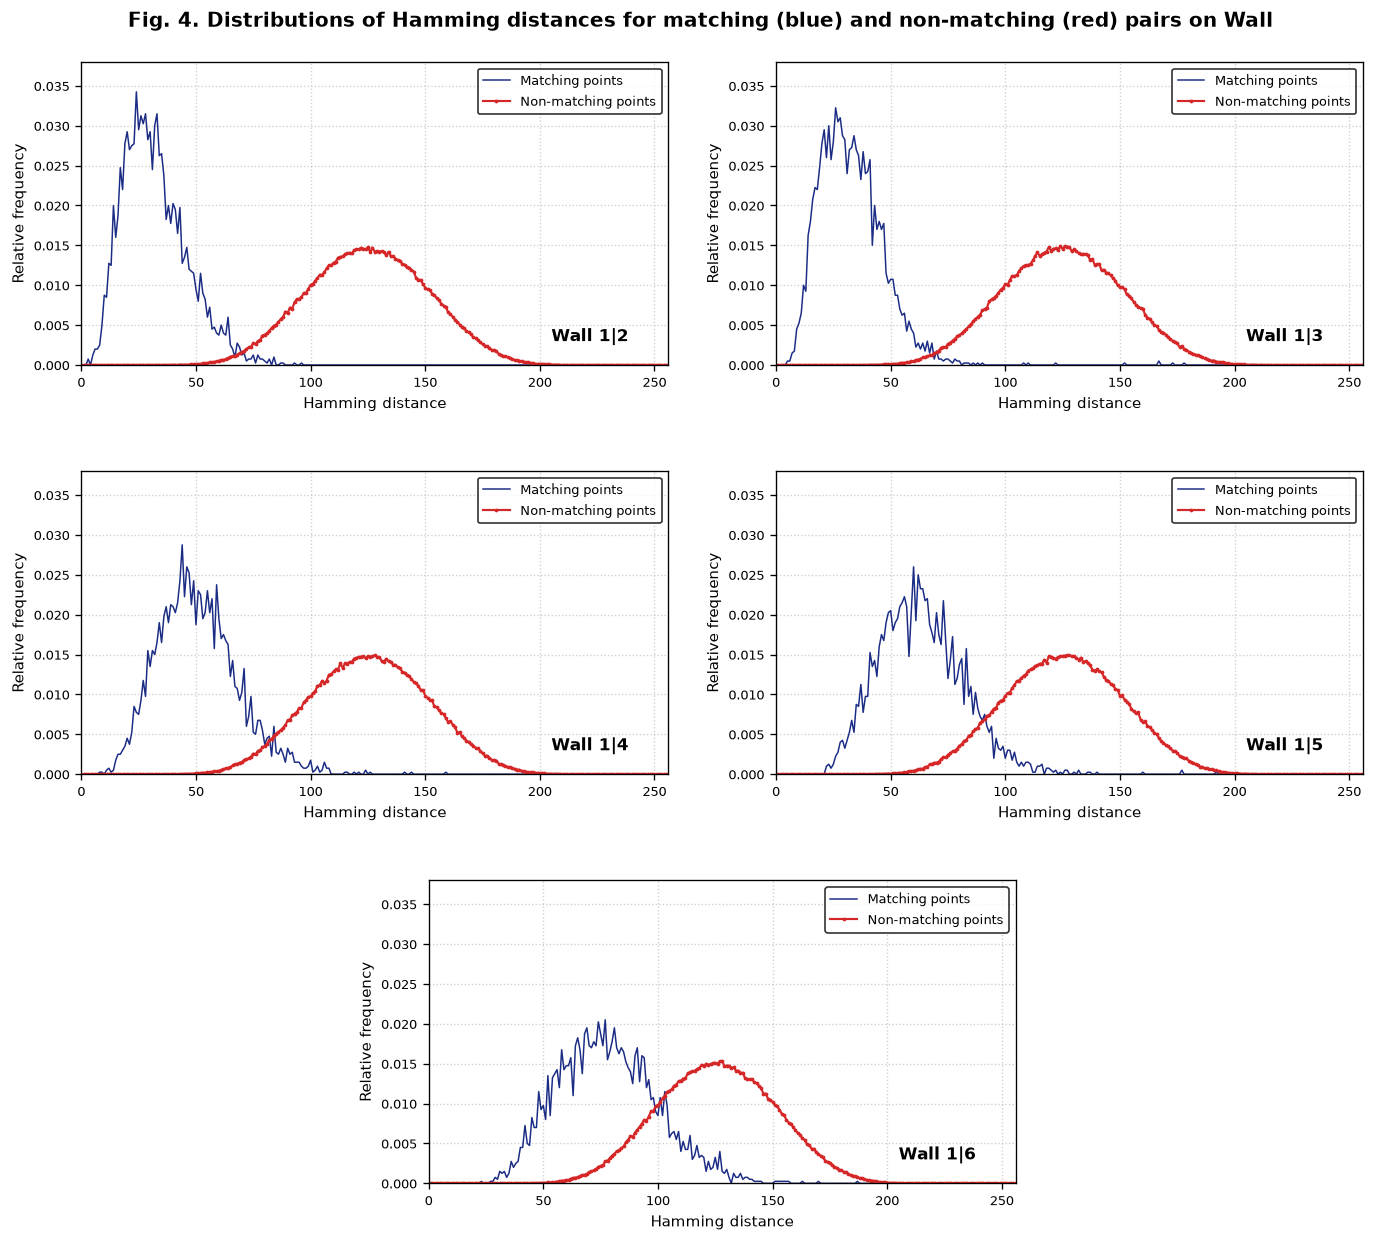

In [8]:
# FIGURA 4: Distribuciones de distancias de Hamming

import os
import cv2
from matplotlib.gridspec import GridSpec

dataset = get_base_dir("Wall")
n_bits = 256
np.random.seed(42)

# Según la Sección 3.2 y 3.3: usamos la geometría G_II con 256 bits (32 bytes) y sigma = 2.0
pares_G2 = generate_brief_pairs(patch_size=31, num_pairs=n_bits, strategy='G_II')
extractor_fig4 = BRIEFExtractor(patch_size=31, num_pairs=n_bits, strategy='G_II', sigma=2.0, pairs=pares_G2)

img1 = cv2.imread(os.path.join(dataset, "img1.ppm"), cv2.IMREAD_GRAYSCALE)

fig = plt.figure(figsize=(12, 10.5), dpi=120)
gs = GridSpec(3, 4, figure=fig, hspace=0.35, wspace=0.45)
posiciones = [gs[0, 0:2], gs[0, 2:4], gs[1, 0:2], gs[1, 2:4], gs[2, 1:3]]

bins = np.arange(0, n_bits + 2) - 0.5
x_vals = np.arange(0, n_bits + 1)

print("Extrayendo ~4000 puntos y calculando distribuciones de distancia de Hamming...")
for idx_plot, t in enumerate(range(2, 7)):
    ax = fig.add_subplot(posiciones[idx_plot])
    img_t = cv2.imread(os.path.join(dataset, f"img{t}.ppm"), cv2.IMREAD_GRAYSCALE)
    H_gt = np.loadtxt(os.path.join(dataset, f"H1to{t}p"))

    # Extraemos ~4000 puntos correspondientes usando nuestra función con Homografía Ground Truth
    kp1, kpt = cargar_puntos_con_homografia(img1, img_t, H_gt, num_puntos=4000, patch_size=31)
    _, d1 = extractor_fig4.compute(img1, kp1)
    _, dt = extractor_fig4.compute(img_t, kpt)

    # Distancias entre pares correspondientes (Matching points: punto i con punto i)
    dist_match = hamming_distance(d1, dt)

    # Distancias entre pares NO correspondientes (Non-matching points: punto i con punto j != i)
    dist_nonmatch = np.concatenate([
        hamming_distance(d1, np.roll(dt, shift, axis=0))
        for shift in range(1, min(100, len(dt)))
    ])

    # Histogramas normalizados (frecuencia relativa)
    hist_match, _ = np.histogram(dist_match, bins=bins, density=True)
    hist_nonmatch, _ = np.histogram(dist_nonmatch, bins=bins, density=True)

    ax.plot(x_vals, hist_match, color='#1b2c85', linewidth=0.9, label='Matching points')
    ax.plot(x_vals, hist_nonmatch, color='#d62728', linewidth=1.3, marker='.', markersize=2.5, label='Non-matching points')

    ax.set_xlim(0, 256)
    ax.set_ylim(0, 0.038)
    ax.set_xticks(np.arange(0, 251, 50))
    ax.set_yticks(np.arange(0, 0.036, 0.005))
    ax.set_xlabel('Hamming distance', fontsize=9)
    ax.set_ylabel('Relative frequency', fontsize=9)
    ax.tick_params(labelsize=8)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.text(205, 0.003, f'Wall 1|{t}', fontsize=10, fontweight='bold')
    ax.legend(loc='upper right', fontsize=8, frameon=True, edgecolor='black')

fig.suptitle('Fig. 4. Distributions of Hamming distances for matching (blue) and non-matching (red) pairs on Wall', fontsize=12, fontweight='bold', y=0.99)
fig.subplots_adjust(top=0.95, bottom=0.06, left=0.07, right=0.96)
plt.show()

Figura 5

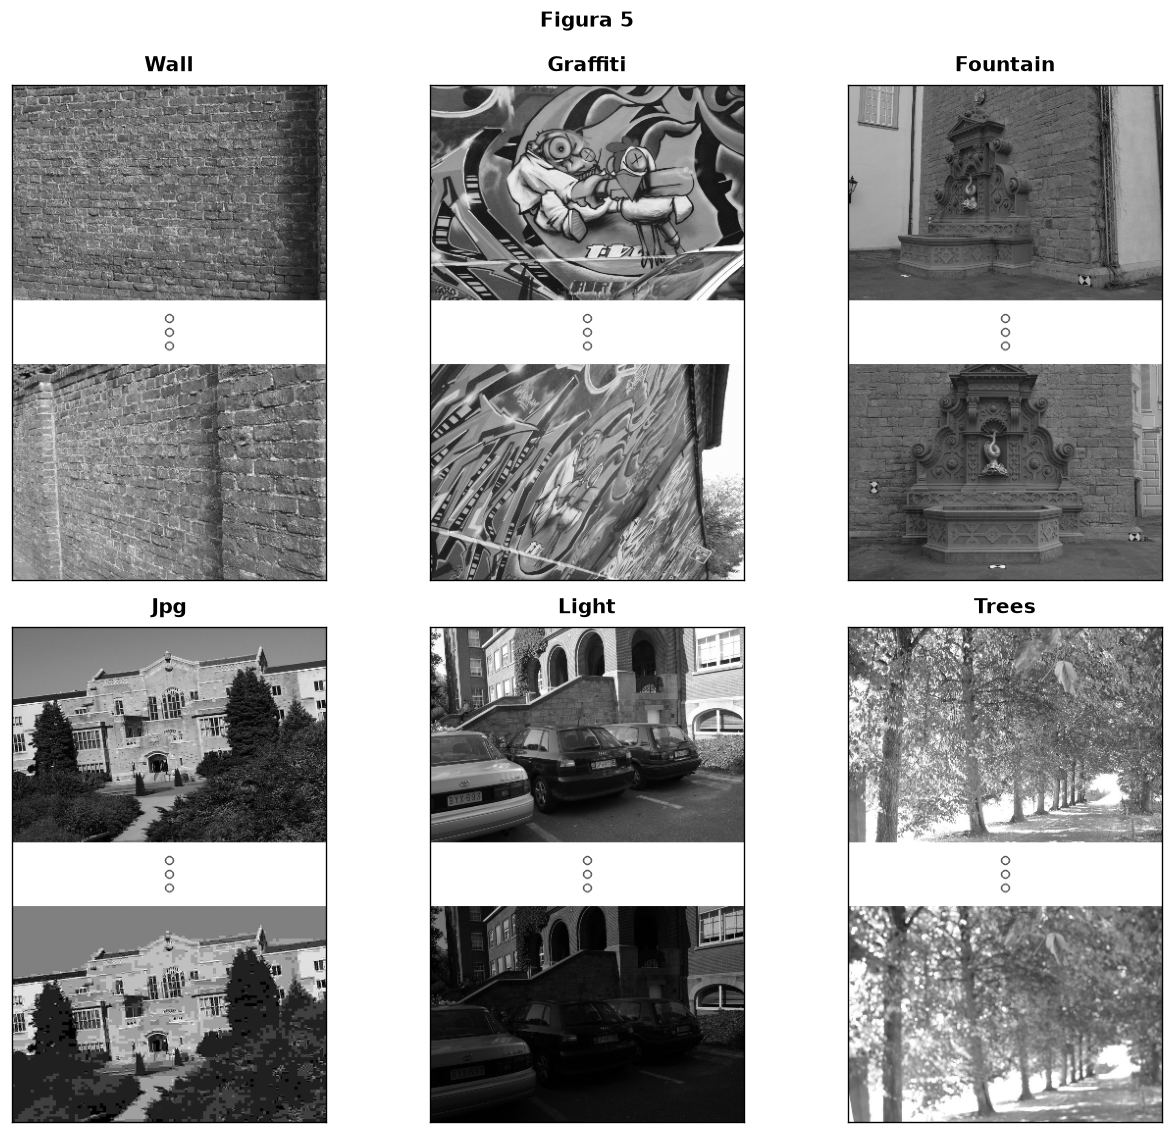

In [9]:
# FIGURA 5: Los 6 datasets de evaluación 
# 
import os
import cv2

datasets_fig5 = ['Wall', 'Graffiti', 'Fountain', 'Jpg', 'Light', 'Trees']
fig, axes = plt.subplots(2, 3, figsize=(11, 9.5), dpi=120)

for ax, nombre_ds in zip(axes.ravel(), datasets_fig5):
    ruta_ds = get_base_dir(nombre_ds)
    f1 = os.path.join(ruta_ds, 'img1.ppm') if os.path.exists(os.path.join(ruta_ds, 'img1.ppm')) else os.path.join(ruta_ds, '0000.jpg')
    f6 = os.path.join(ruta_ds, 'img6.ppm') if os.path.exists(os.path.join(ruta_ds, 'img6.ppm')) else os.path.join(ruta_ds, '0005.jpg')

    im1 = cv2.imread(f1, cv2.IMREAD_GRAYSCALE)
    im6 = cv2.imread(f6, cv2.IMREAD_GRAYSCALE)
    im1_r = cv2.resize(im1, (320, 220))
    im6_r = cv2.resize(im6, (320, 220))

    # Separador blanco con 3 círculos verticales como en la Figura 5 del paper
    sep = np.full((65, 320), 255, dtype=np.uint8)
    for cy in [18, 32, 46]:
        cv2.circle(sep, (160, cy), 4, 60, 1, cv2.LINE_AA)

    bloque = np.vstack([im1_r, sep, im6_r])
    ax.imshow(bloque, cmap='gray', vmin=0, vmax=255)
    ax.set_title(nombre_ds, fontsize=12, fontweight='bold', pad=8)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_linewidth(0.8)

fig.suptitle('Figura 5', fontsize=12, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


Figura 6

Calculando Figura 6 en los 6 datasets (N=512)...


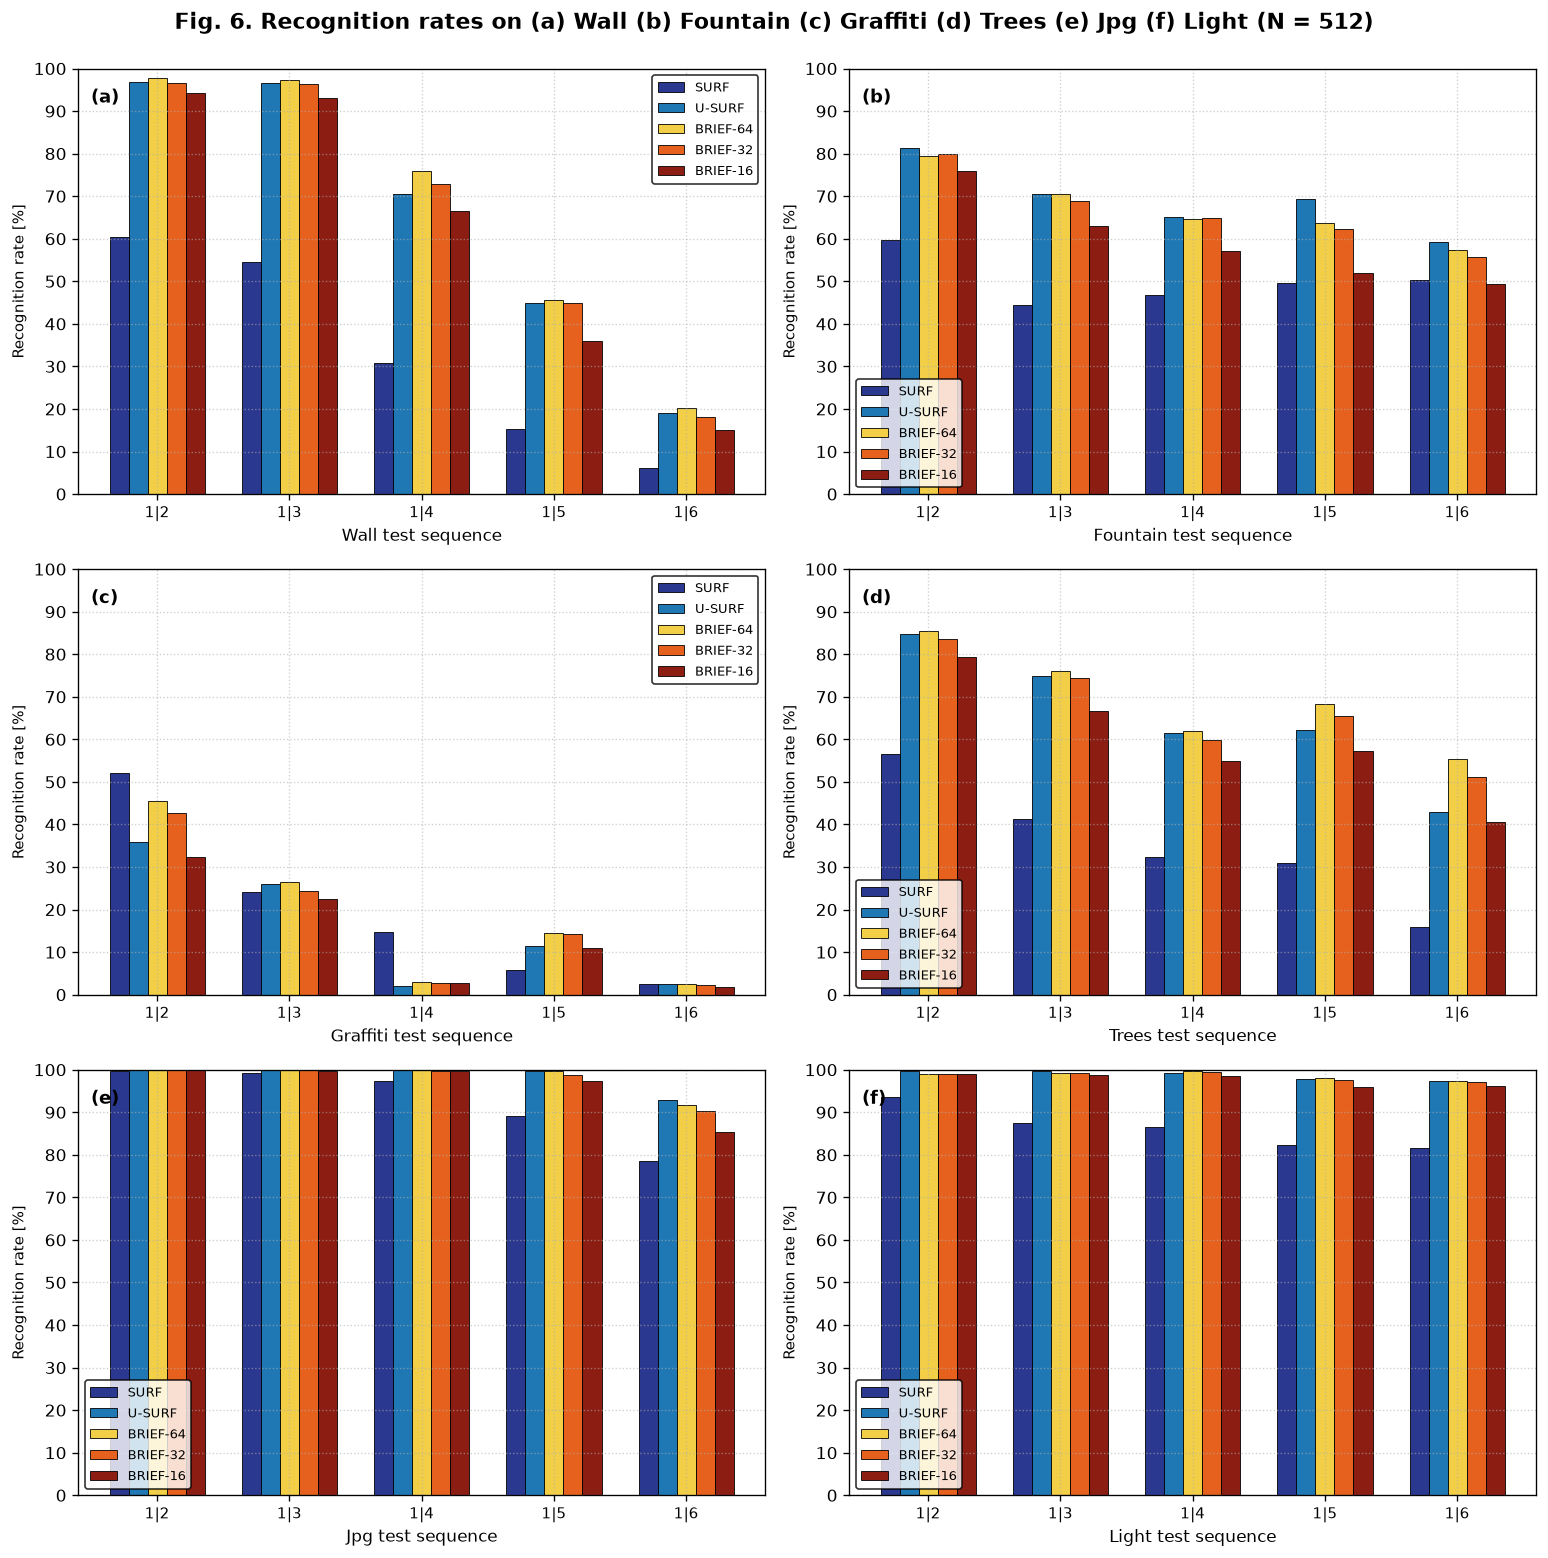

In [10]:
# FIGURA 6: Tasas de reconocimiento en los 6 datasets (N = 512 puntos)

import importlib
import src.descriptor, src.matcher
importlib.reload(src.descriptor)
importlib.reload(src.matcher)
from src.descriptor import BRIEFExtractor, SURF64Extractor
from src.matcher import evaluar_reconocimiento_general, get_base_dir

np.random.seed(42)
pares_512 = generate_brief_pairs(31, 512, 'G_II')
pares_256 = (pares_512[0][:256], pares_512[1][:256])
pares_128 = (pares_512[0][:128], pares_512[1][:128])

modelos_fig6 = [
    ('SURF',     SURF64Extractor(upright=False),                        '#2b388f'),
    ('U-SURF',   SURF64Extractor(upright=True),                         '#1f78b4'),
    ('BRIEF-64', BRIEFExtractor(31, 512, 'G_II', 2.0, pairs=pares_512), '#f2cf46'),
    ('BRIEF-32', BRIEFExtractor(31, 256, 'G_II', 2.0, pairs=pares_256), '#e6611e'),
    ('BRIEF-16', BRIEFExtractor(31, 128, 'G_II', 2.0, pairs=pares_128), '#8c1d13'),
]

secuencias_fig6 = [
    ('Wall',     '(a)', 'Wall test sequence'),
    ('Fountain', '(b)', 'Fountain test sequence'),
    ('Graffiti', '(c)', 'Graffiti test sequence'),
    ('Trees',    '(d)', 'Trees test sequence'),
    ('Jpg',      '(e)', 'Jpg test sequence'),
    ('Light',    '(f)', 'Light test sequence'),
]

fig, axes = plt.subplots(3, 2, figsize=(13, 13), dpi=120)
etiquetas_x = ['1|2', '1|3', '1|4', '1|5', '1|6']
x = np.arange(5)
ancho_barra = 0.72 / len(modelos_fig6)

print("Calculando Figura 6 en los 6 datasets (N=512)...")
for ax, (ds_name, letra, xlabel_txt) in zip(axes.ravel(), secuencias_fig6):
    for j, (label_m, ext_m, color_m) in enumerate(modelos_fig6):
        tasas_ds, _ = evaluar_reconocimiento_general(ds_name, ext_m, num_puntos=512)
        offset = (j - len(modelos_fig6) / 2 + 0.5) * ancho_barra
        ax.bar(x + offset, tasas_ds, width=ancho_barra, label=label_m, color=color_m, edgecolor='black', linewidth=0.5)

    ax.set_ylim(0, 100)
    ax.set_yticks(np.arange(0, 101, 10))
    ax.set_xticks(x)
    ax.set_xticklabels(etiquetas_x, fontsize=9)
    ax.set_xlabel(xlabel_txt, fontsize=10)
    ax.set_ylabel('Recognition rate [%]', fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.text(-0.5, 92, letra, fontsize=11, fontweight='bold')
    ax.legend(loc='lower left' if ds_name in ['Fountain', 'Trees', 'Jpg', 'Light'] else 'upper right', fontsize=8, frameon=True, edgecolor='black')

fig.suptitle('Fig. 6. Recognition rates on (a) Wall (b) Fountain (c) Graffiti (d) Trees (e) Jpg (f) Light (N = 512)', fontsize=13, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


Figura 7

Calculando Figura 7 para N = 512, 1024, 2048, 4096...


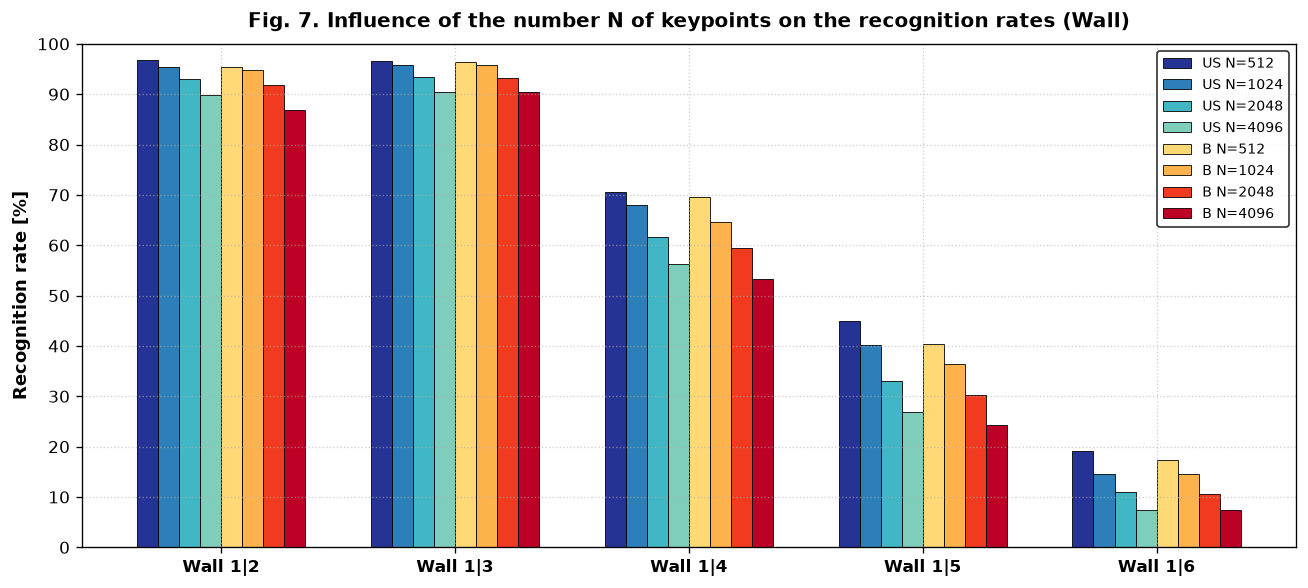

In [11]:
# FIGURA 7: Influencia del número N de keypoints (512, 1024, 2048, 4096) en Wall

N_lista = [512, 1024, 2048, 4096]
np.random.seed(42)
pares_256 = generate_brief_pairs(31, 256, 'G_II')
ext_usurf = SURF64Extractor(upright=True)
ext_b32 = BRIEFExtractor(31, 256, 'G_II', 2.0, pairs=pares_256)

series_fig7 = []
etiquetas_fig7 = []
colores_fig7 = ['#253494', '#2c7fb8', '#41b6c4', '#7fcdbb', '#fed976', '#feb24c', '#f03b20', '#bd0026']

print("Calculando Figura 7 para N = 512, 1024, 2048, 4096...")
for N_val in N_lista:
    tasas_us, nombres_pares = evaluar_reconocimiento_general('Wall', ext_usurf, num_puntos=N_val)
    series_fig7.append(tasas_us)
    etiquetas_fig7.append(f'US N={N_val}')

for N_val in N_lista:
    tasas_b, nombres_pares = evaluar_reconocimiento_general('Wall', ext_b32, num_puntos=N_val)
    series_fig7.append(tasas_b)
    etiquetas_fig7.append(f'B N={N_val}')

matriz_fig7 = np.array(series_fig7).T  # (5 pares, 8 barras)

fig, ax = plt.subplots(figsize=(11, 5.0), dpi=120)
x = np.arange(5)
num_barras = len(series_fig7)
ancho_barra = 0.72 / num_barras

for j in range(num_barras):
    offset = (j - num_barras / 2 + 0.5) * ancho_barra
    ax.bar(x + offset, matriz_fig7[:, j], width=ancho_barra, label=etiquetas_fig7[j], color=colores_fig7[j], edgecolor='black', linewidth=0.5)

ax.set_ylim(0, 100)
ax.set_yticks(np.arange(0, 101, 10))
ax.set_xticks(x)
ax.set_xticklabels(nombres_pares, fontsize=10, fontweight='bold')
ax.set_ylabel('Recognition rate [%]', fontsize=11, fontweight='bold')
ax.set_title('Fig. 7. Influence of the number N of keypoints on the recognition rates (Wall)', fontsize=12, fontweight='bold', pad=10)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper right', fontsize=8.5, frameon=True, edgecolor='black')
plt.tight_layout()
plt.show()


Figura 8

Calculando curvas de la Figura 8 (de 8 a 512 pruebas binarias)...


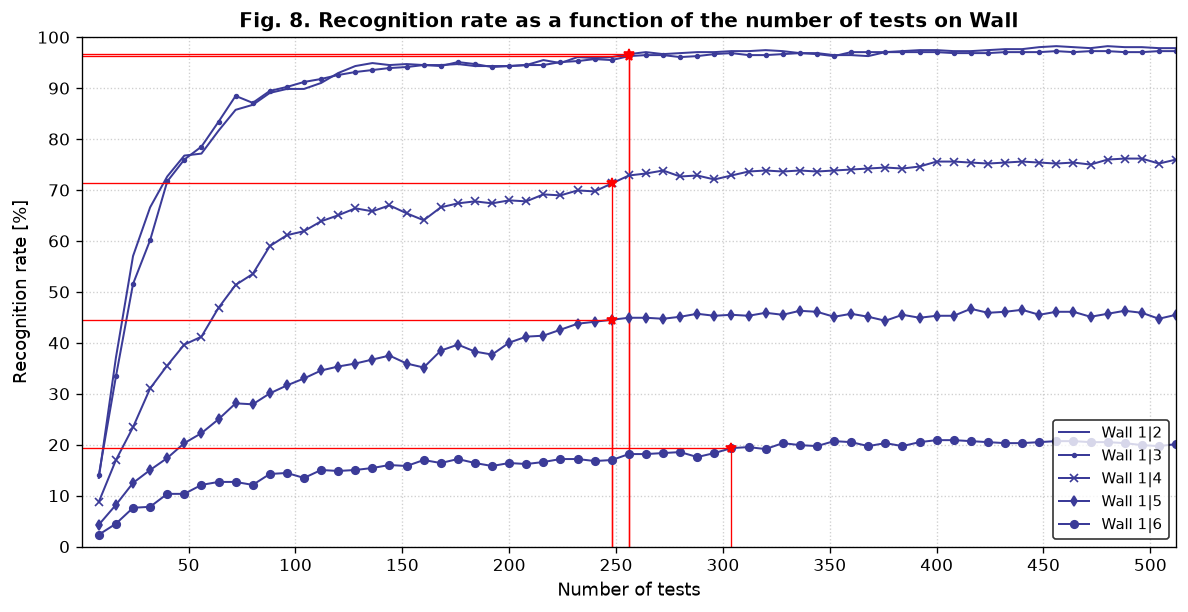

In [12]:
# FIGURA 8: Tasa de reconocimiento en función del número de pruebas en Wall

dataset = get_base_dir('Wall')
img1 = cv2.imread(os.path.join(dataset, 'img1.ppm'), cv2.IMREAD_GRAYSCALE)

np.random.seed(42)
pares_512 = generate_brief_pairs(31, 512, 'G_II')
ext_full = BRIEFExtractor(31, 512, 'G_II', 2.0, pairs=pares_512)
ext_usurf = SURF64Extractor(upright=True)

num_tests_list = np.arange(8, 513, 8)
curvas_fig8 = {t: [] for t in range(2, 7)}
tasas_usurf_ref = {}

print("Calculando curvas de la Figura 8 (de 8 a 512 pruebas binarias)...")
for t in range(2, 7):
    img_t = cv2.imread(os.path.join(dataset, f'img{t}.ppm'), cv2.IMREAD_GRAYSCALE)
    H_gt = np.loadtxt(os.path.join(dataset, f'H1to{t}p'))
    kp1, kpt = cargar_puntos_con_homografia(img1, img_t, H_gt, num_puntos=512, patch_size=31)

    # Extraer los 512 bits crudos una sola vez y evaluar prefijos de longitud k
    _, bits1 = ext_full.compute(img1, kp1, return_bits=True)
    _, bitst = ext_full.compute(img_t, kpt, return_bits=True)

    # Tasa de referencia U-SURF en los mismos puntos
    _, d_us1 = ext_usurf.compute(img1, kp1)
    _, d_ust = ext_usurf.compute(img_t, kpt)
    tasas_usurf_ref[t] = (np.sum(np.argmax(d_us1 @ d_ust.T, axis=1) == np.arange(len(d_us1))) / len(kp1)) * 100.0

    for k in num_tests_list:
        pk1 = np.packbits(bits1[:, :k], axis=1)
        pkt = np.packbits(bitst[:, :k], axis=1)
        aciertos = sum(1 for i in range(len(pk1)) if int(np.argmin(hamming_distance(pk1[i], pkt))) == i)
        curvas_fig8[t].append((aciertos / len(kp1)) * 100.0)

fig, ax = plt.subplots(figsize=(10, 5.2), dpi=120)
marcadores = [None, '.', 'x', 'd', 'o']

for idx_m, t in enumerate(range(2, 7)):
    y_vals = np.array(curvas_fig8[t])
    ax.plot(num_tests_list, y_vals, color='#3b3b98', marker=marcadores[idx_m], markersize=4.5, linewidth=1.2, label=f'Wall 1|{t}')

    # Punto donde BRIEF alcanza la tasa de U-SURF (líneas rojas como en el paper)
    meta = min(tasas_usurf_ref[t], y_vals.max())
    idx_cruce = int(np.argmax(y_vals >= meta - 0.5))
    k_cruce = num_tests_list[idx_cruce]
    y_cruce = y_vals[idx_cruce]
    ax.plot([0, k_cruce], [y_cruce, y_cruce], color='red', linewidth=0.8)
    ax.plot([k_cruce, k_cruce], [0, y_cruce], color='red', linewidth=0.8)
    ax.plot(k_cruce, y_cruce, marker='*', color='red', markersize=6)

ax.set_xlim(0, 512)
ax.set_ylim(0, 100)
ax.set_xticks(np.arange(50, 501, 50))
ax.set_yticks(np.arange(0, 101, 10))
ax.set_xlabel('Number of tests', fontsize=11)
ax.set_ylabel('Recognition rate [%]', fontsize=11)
ax.set_title('Fig. 8. Recognition rate as a function of the number of tests on Wall', fontsize=12, fontweight='bold')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='lower right', fontsize=9, frameon=True, edgecolor='black')
plt.tight_layout()
plt.show()


Figura 9

Calculando Figura 9 (Izquierda: detectores; Derecha: rotación 0° a 180°)...


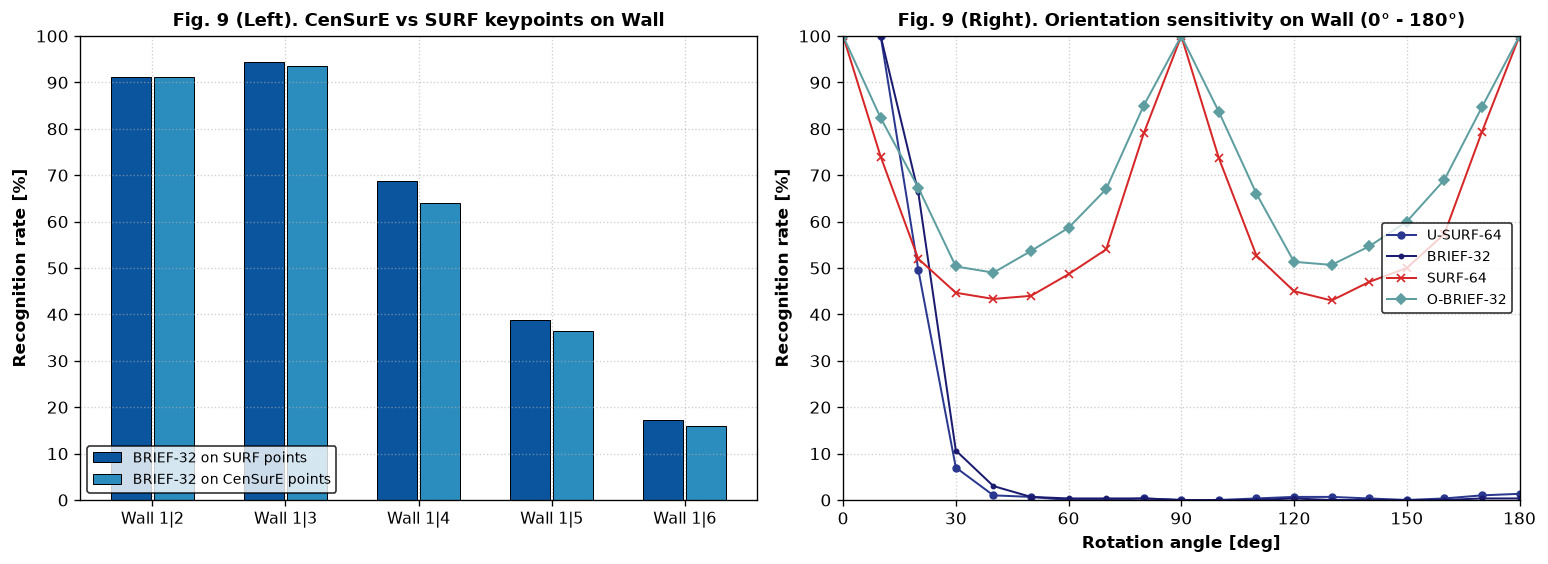

In [13]:
# FIGURA 9: Izquierda (SURF vs CenSurE keypoints) y Derecha (Rotación 0..180 deg)

from src.descriptor import OBRIEFExtractor

np.random.seed(42)
pares_256 = generate_brief_pairs(31, 256, 'G_II')
ext_b32 = BRIEFExtractor(31, 256, 'G_II', 2.0, pairs=pares_256)
ext_ob32 = OBRIEFExtractor(31, 256, 'G_II', 2.0, pairs=pares_256)
ext_surf = SURF64Extractor(upright=False)
ext_usurf = SURF64Extractor(upright=True)

# 1. Figura 9 (Izquierda): SURF points vs CenSurE points en Wall
tasas_surf_pts, nombres_pares = evaluar_reconocimiento_general('Wall', ext_b32, num_puntos=512, detector='SURF')
tasas_censure_pts, _ = evaluar_reconocimiento_general('Wall', ext_b32, num_puntos=512, detector='CenSurE')

# 2. Figura 9 (Derecha): Rotación de img1 de Wall de 0 a 180 grados
dataset = get_base_dir('Wall')
img1 = cv2.imread(os.path.join(dataset, 'img1.ppm'), cv2.IMREAD_GRAYSCALE)
h, w = img1.shape
centro = (w / 2.0, h / 2.0)

angulos = np.linspace(0, 180, 19)
curvas_rot = {'U-SURF-64': [], 'BRIEF-32': [], 'SURF-64': [], 'O-BRIEF-32': []}

print("Calculando Figura 9 (Izquierda: detectores; Derecha: rotación 0° a 180°)...")
for ang in angulos:
    M = cv2.getRotationMatrix2D(centro, float(ang), 1.0)
    img_rot = cv2.warpAffine(img1, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    H_rot = np.vstack([M, [0.0, 0.0, 1.0]])

    kp1, kp_rot = cargar_puntos_con_homografia(img1, img_rot, H_rot, num_puntos=300, patch_size=31)

    for nombre_m, ext_m in [('U-SURF-64', ext_usurf), ('BRIEF-32', ext_b32), ('SURF-64', ext_surf), ('O-BRIEF-32', ext_ob32)]:
        _, d1 = ext_m.compute(img1, kp1)
        _, dr = ext_m.compute(img_rot, kp_rot)
        if d1.dtype == np.uint8:
            ok = sum(1 for i in range(len(d1)) if int(np.argmin(hamming_distance(d1[i], dr))) == i)
        else:
            ok = int(np.sum(np.argmax(d1 @ dr.T, axis=1) == np.arange(len(d1))))
        curvas_rot[nombre_m].append((ok / len(kp1)) * 100.0)

fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(13, 4.8), dpi=120)

# Subplot Izquierdo
x = np.arange(5)
ax_l.bar(x - 0.16, tasas_surf_pts, width=0.30, label='BRIEF-32 on SURF points', color='#0b559f', edgecolor='black', linewidth=0.6)
ax_l.bar(x + 0.16, tasas_censure_pts, width=0.30, label='BRIEF-32 on CenSurE points', color='#2b8cbe', edgecolor='black', linewidth=0.6)
ax_l.set_ylim(0, 100)
ax_l.set_yticks(np.arange(0, 101, 10))
ax_l.set_xticks(x)
ax_l.set_xticklabels(nombres_pares, fontsize=9.5)
ax_l.set_ylabel('Recognition rate [%]', fontsize=10, fontweight='bold')
ax_l.set_title('Fig. 9 (Left). CenSurE vs SURF keypoints on Wall', fontsize=11, fontweight='bold')
ax_l.grid(True, linestyle=':', alpha=0.6)
ax_l.legend(loc='lower left', fontsize=8.5, frameon=True, edgecolor='black')

# Subplot Derecho
ax_r.plot(angulos, curvas_rot['U-SURF-64'],  color='#2b388f', marker='o', markersize=4, linewidth=1.2, label='U-SURF-64')
ax_r.plot(angulos, curvas_rot['BRIEF-32'],   color='#1b1b6f', marker='.', markersize=5, linewidth=1.2, label='BRIEF-32')
ax_r.plot(angulos, curvas_rot['SURF-64'],    color='#d62728', marker='x', markersize=5, linewidth=1.2, label='SURF-64')
ax_r.plot(angulos, curvas_rot['O-BRIEF-32'], color='#5f9ea0', marker='D', markersize=4, linewidth=1.2, label='O-BRIEF-32')
ax_r.set_xlim(0, 180)
ax_r.set_ylim(0, 100)
ax_r.set_xticks(np.arange(0, 181, 30))
ax_r.set_yticks(np.arange(0, 101, 10))
ax_r.set_xlabel('Rotation angle [deg]', fontsize=10, fontweight='bold')
ax_r.set_ylabel('Recognition rate [%]', fontsize=10, fontweight='bold')
ax_r.set_title('Fig. 9 (Right). Orientation sensitivity on Wall (0° - 180°)', fontsize=11, fontweight='bold')
ax_r.grid(True, linestyle=':', alpha=0.6)
ax_r.legend(loc='center right', fontsize=8.5, frameon=True, edgecolor='black')

plt.tight_layout()
plt.show()


Tabla

In [14]:
# TABLA DE TIEMPOS: 512 keypoints (ms)

import time

dataset = get_base_dir('Wall')
img1 = cv2.imread(os.path.join(dataset, 'img1.ppm'), cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread(os.path.join(dataset, 'img2.ppm'), cv2.IMREAD_GRAYSCALE)
H_gt = np.loadtxt(os.path.join(dataset, 'H1to2p'))

kp1_512, kp2_512 = cargar_puntos_con_homografia(img1, img2, H_gt, num_puntos=512, patch_size=31)

np.random.seed(42)
descriptores_tabla = [
    ('BRIEF-16', BRIEFExtractor(31, 128, 'G_II', 2.0)),
    ('BRIEF-32', BRIEFExtractor(31, 256, 'G_II', 2.0)),
    ('BRIEF-64', BRIEFExtractor(31, 512, 'G_II', 2.0)),
    ('SURF-64',  SURF64Extractor(upright=False)),
]

n_runs = 20
tiempos_comp = {}
tiempos_match = {}

for nombre_d, ext_d in descriptores_tabla:
    # Paso 2: Descriptor computation (para 512 keypoints)
    t0 = time.perf_counter()
    for _ in range(n_runs):
        _, d1 = ext_d.compute(img1, kp1_512)
    t_comp_ms = ((time.perf_counter() - t0) / n_runs) * 1000.0
    _, d2 = ext_d.compute(img2, kp2_512)

    # Paso 3: Matching (exact NN para 512x512 descriptores)
    t1 = time.perf_counter()
    for _ in range(n_runs):
        if d1.dtype == np.uint8:
            _ = [int(np.argmin(hamming_distance(d1[i], d2))) for i in range(len(d1))]
        else:
            _ = [int(np.argmin( np.linalg.norm(d2 - d1[i], axis=1) )) for i in range(len(d1))]
    t_match_ms = ((time.perf_counter() - t1) / n_runs) * 1000.0

    tiempos_comp[nombre_d] = t_comp_ms
    tiempos_match[nombre_d] = t_match_ms

print("=" * 74)
print(" Timing results for the second and third steps for 512 keypoints [ms]")
print("=" * 74)
print(f"{'Step':<26} {'BRIEF-16':>10} {'BRIEF-32':>10} {'BRIEF-64':>10} {'SURF-64':>10}")
print("-" * 74)
print(f"{'Descriptor computation':<26} {tiempos_comp['BRIEF-16']:>10.2f} {tiempos_comp['BRIEF-32']:>10.2f} {tiempos_comp['BRIEF-64']:>10.2f} {tiempos_comp['SURF-64']:>10.2f}")
print(f"{'Matching (exact NN)':<26} {tiempos_match['BRIEF-16']:>10.2f} {tiempos_match['BRIEF-32']:>10.2f} {tiempos_match['BRIEF-64']:>10.2f} {tiempos_match['SURF-64']:>10.2f}")
print("-" * 74)
print("Valores reportados en el Paper (Calonder et al., 2010, pág. 790):")
print(f"{'Descriptor computation':<26} {'8.18':>10} {'8.87':>10} {'9.57':>10} {'335.00':>10}")
print(f"{'Matching (exact NN)':<26} {'2.19':>10} {'4.35':>10} {'8.16':>10} {'28.30':>10}")
print("=" * 74)


 Timing results for the second and third steps for 512 keypoints [ms]
Step                         BRIEF-16   BRIEF-32   BRIEF-64    SURF-64
--------------------------------------------------------------------------
Descriptor computation          14.13      20.36      35.86      99.61
Matching (exact NN)             51.80      73.77     143.30      43.08
--------------------------------------------------------------------------
Valores reportados en el Paper (Calonder et al., 2010, pág. 790):
Descriptor computation           8.18       8.87       9.57     335.00
Matching (exact NN)              2.19       4.35       8.16      28.30


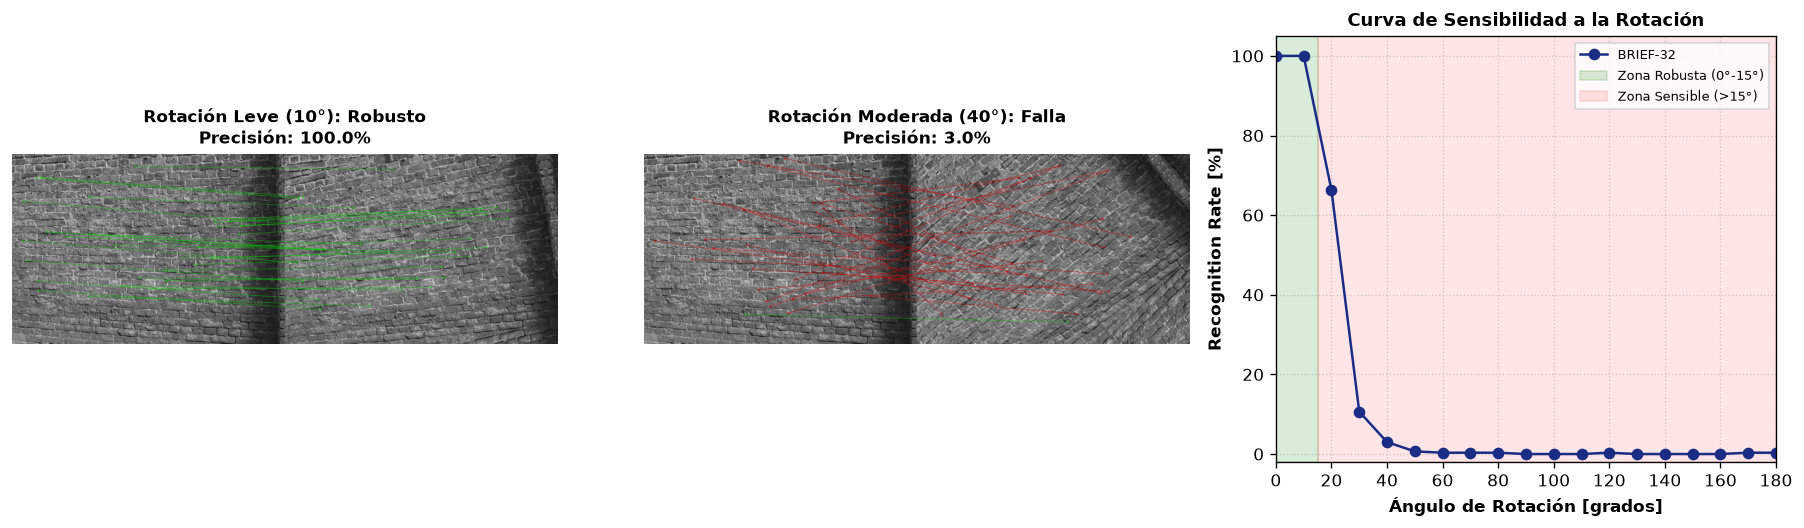

In [15]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from src.sampling import generate_brief_pairs
from src.descriptor import BRIEFExtractor
from src.matcher import get_base_dir, cargar_puntos_con_homografia, hamming_distance

# 1. Cargar imagen base
dataset = get_base_dir("Wall")
img1 = cv2.imread(os.path.join(dataset, "img1.ppm"), cv2.IMREAD_GRAYSCALE)
h, w = img1.shape
centro = (w / 2.0, h / 2.0)

# 2. Configurar BRIEF-32 (256 bits, G_II, sigma=2.0)
np.random.seed(42)
pares = generate_brief_pairs(patch_size=31, num_pairs=256, strategy='G_II')
extractor = BRIEFExtractor(patch_size=31, num_pairs=256, strategy='G_II', sigma=2.0, pairs=pares)

# Función para dibujar matches con líneas verdes (éxito) y rojas (fallo)
def graficar_matches(ax, img_a, img_b, kp_a, kp_b, d_a, d_b, titulo, num_lineas=30):
    ha, wa = img_a.shape
    hb, wb = img_b.shape
    lienzo = np.full((max(ha, hb), wa + wb), 255, dtype=np.uint8)
    lienzo[:ha, :wa] = img_a
    lienzo[:hb, wa:] = img_b
    lienzo_rgb = cv2.cvtColor(lienzo, cv2.COLOR_GRAY2RGB)

    pred_indices = [int(np.argmin(hamming_distance(d_a[i], d_b))) for i in range(len(d_a))]
    aciertos = sum(1 for i, p in enumerate(pred_indices) if p == i)
    tasa = (aciertos / len(d_a)) * 100.0

    indices_muestreo = np.random.choice(len(d_a), min(num_lineas, len(d_a)), replace=False)
    for i in indices_muestreo:
        pt1 = (int(round(kp_a[i].pt[0])), int(round(kp_a[i].pt[1])))
        pt2 = (int(round(kp_b[pred_indices[i]].pt[0])) + wa, int(round(kp_b[pred_indices[i]].pt[1])))
        color = (0, 200, 0) if pred_indices[i] == i else (220, 0, 0)
        cv2.line(lienzo_rgb, pt1, pt2, color, 1, cv2.LINE_AA)
        cv2.circle(lienzo_rgb, pt1, 3, color, -1)
        cv2.circle(lienzo_rgb, pt2, 3, color, -1)

    ax.imshow(lienzo_rgb)
    ax.set_title(f"{titulo}\nPrecisión: {tasa:.1f}%", fontsize=10, fontweight='bold')
    ax.axis('off')

# 3. Evaluar curva cuantitativa y guardar ejemplos visuales a 10° y 40°
angulos = np.arange(0, 181, 10)  # [0, 10, 20, 30, 40, ...]
tasas_rot = []
ejemplos = {}

for ang in angulos:
    M = cv2.getRotationMatrix2D(centro, float(ang), 1.0)
    img_rot = cv2.warpAffine(img1, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    H_rot = np.vstack([M, [0.0, 0.0, 1.0]])

    kp1, kpr = cargar_puntos_con_homografia(img1, img_rot, H_rot, num_puntos=300, patch_size=31)
    _, d1 = extractor.compute(img1, kp1)
    _, dr = extractor.compute(img_rot, kpr)

    ok = sum(1 for i in range(len(d1)) if int(np.argmin(hamming_distance(d1[i], dr))) == i)
    tasa = (ok / len(d1)) * 100.0
    tasas_rot.append(tasa)

    # Guardamos los ejemplos de 10° y 40° (ambos existen en angulos)
    if ang in [10, 40]:
        ejemplos[ang] = (img_rot, kp1, kpr, d1, dr)

# 4. Graficar en una sola figura
fig = plt.figure(figsize=(15, 4.5), dpi=120)
gs = fig.add_gridspec(1, 3, width_ratios=[1.2, 1.2, 1.1])

ax1 = fig.add_subplot(gs[0])
img_rot10, kp1_10, kpr_10, d1_10, dr_10 = ejemplos[10]
graficar_matches(ax1, img1, img_rot10, kp1_10, kpr_10, d1_10, dr_10, "Rotación Leve (10°): Robusto")

ax2 = fig.add_subplot(gs[1])
img_rot40, kp1_40, kpr_40, d1_40, dr_40 = ejemplos[40]
graficar_matches(ax2, img1, img_rot40, kp1_40, kpr_40, d1_40, dr_40, "Rotación Moderada (40°): Falla")

ax3 = fig.add_subplot(gs[2])
ax3.plot(angulos, tasas_rot, marker='o', color='#1b2c85', linewidth=1.5, label='BRIEF-32')
ax3.axvspan(0, 15, color='green', alpha=0.15, label='Zona Robusta (0°-15°)')
ax3.axvspan(15, 180, color='red', alpha=0.10, label='Zona Sensible (>15°)')
ax3.set_xlim(0, 180)
ax3.set_ylim(-2, 105)
ax3.set_xlabel('Ángulo de Rotación [grados]', fontsize=10, fontweight='bold')
ax3.set_ylabel('Recognition Rate [%]', fontsize=10, fontweight='bold')
ax3.set_title('Curva de Sensibilidad a la Rotación', fontsize=11, fontweight='bold')
ax3.grid(True, linestyle=':', alpha=0.6)
ax3.legend(fontsize=8, loc='upper right')

plt.tight_layout()
plt.show()


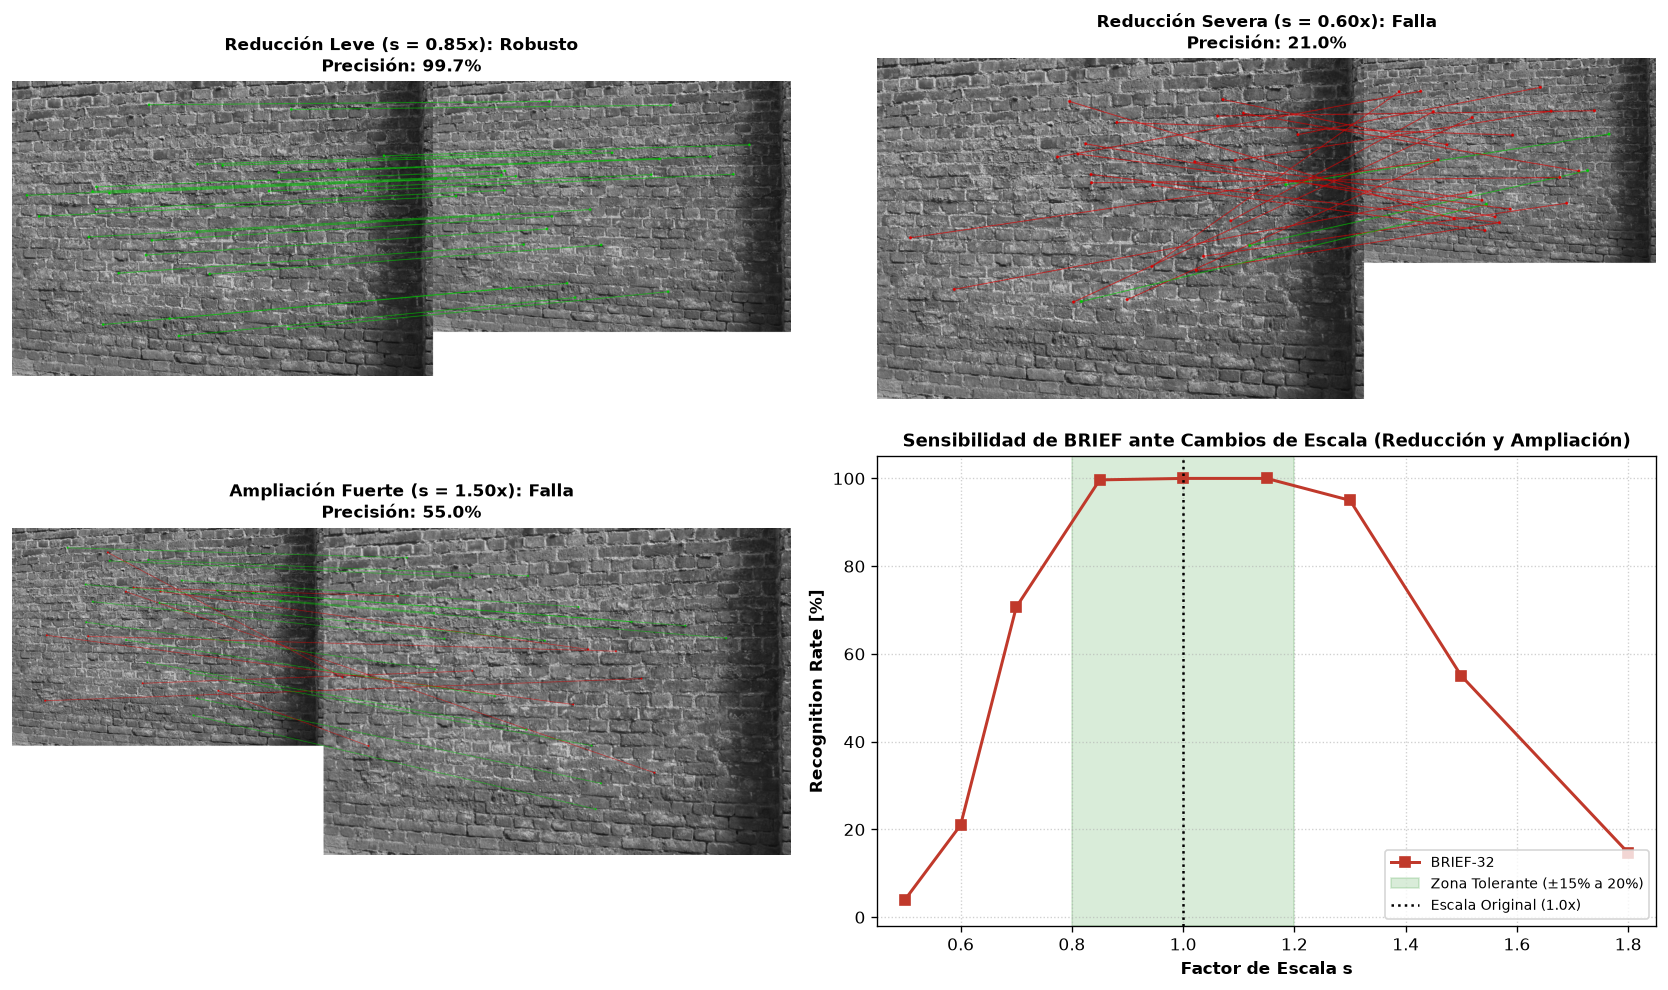

In [16]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from src.sampling import generate_brief_pairs
from src.descriptor import BRIEFExtractor
from src.matcher import get_base_dir, cargar_puntos_con_homografia, hamming_distance

# 1. Cargar imagen base
dataset = get_base_dir("Wall")
img1 = cv2.imread(os.path.join(dataset, "img1.ppm"), cv2.IMREAD_GRAYSCALE)

# 2. Configurar BRIEF-32 (256 bits, G_II, sigma=2.0)
np.random.seed(42)
pares = generate_brief_pairs(patch_size=31, num_pairs=256, strategy='G_II')
extractor = BRIEFExtractor(patch_size=31, num_pairs=256, strategy='G_II', sigma=2.0, pairs=pares)

# Función para graficar matches con líneas verdes (éxito) y rojas (fallo)
def graficar_matches(ax, img_a, img_b, kp_a, kp_b, d_a, d_b, titulo, num_lineas=25):
    ha, wa = img_a.shape
    hb, wb = img_b.shape
    lienzo = np.full((max(ha, hb), wa + wb), 255, dtype=np.uint8)
    lienzo[:ha, :wa] = img_a
    lienzo[:hb, wa:wa+wb] = img_b
    lienzo_rgb = cv2.cvtColor(lienzo, cv2.COLOR_GRAY2RGB)

    pred_indices = [int(np.argmin(hamming_distance(d_a[i], d_b))) for i in range(len(d_a))]
    aciertos = sum(1 for i, p in enumerate(pred_indices) if p == i)
    tasa = (aciertos / len(d_a)) * 100.0

    indices_muestreo = np.random.choice(len(d_a), min(num_lineas, len(d_a)), replace=False)
    for i in indices_muestreo:
        pt1 = (int(round(kp_a[i].pt[0])), int(round(kp_a[i].pt[1])))
        pt2 = (int(round(kp_b[pred_indices[i]].pt[0])) + wa, int(round(kp_b[pred_indices[i]].pt[1])))
        color = (0, 200, 0) if pred_indices[i] == i else (220, 0, 0)
        cv2.line(lienzo_rgb, pt1, pt2, color, 1, cv2.LINE_AA)
        cv2.circle(lienzo_rgb, pt1, 3, color, -1)
        cv2.circle(lienzo_rgb, pt2, 3, color, -1)

    ax.imshow(lienzo_rgb)
    ax.set_title(f"{titulo}\nPrecisión: {tasa:.1f}%", fontsize=10, fontweight='bold')
    ax.axis('off')

# 3. Evaluar curva cuantitativa y guardar ejemplos específicos
escalas = [0.5, 0.6, 0.7, 0.85, 1.0, 1.15, 1.3, 1.5, 1.8]
tasas_esc = []
ejemplos_esc = {}

for s in escalas:
    img_sc = cv2.resize(img1, (0, 0), fx=s, fy=s, interpolation=cv2.INTER_LINEAR)
    H_sc = np.array([[s, 0.0, 0.0],
                     [0.0, s, 0.0],
                     [0.0, 0.0, 1.0]])

    kp1, kps = cargar_puntos_con_homografia(img1, img_sc, H_sc, num_puntos=300, patch_size=31)
    _, d1 = extractor.compute(img1, kp1)
    _, ds = extractor.compute(img_sc, kps)

    ok = sum(1 for i in range(len(d1)) if int(np.argmin(hamming_distance(d1[i], ds))) == i)
    tasa = (ok / len(d1)) * 100.0
    tasas_esc.append(tasa)

    if s in [0.85, 0.60, 1.50]:
        ejemplos_esc[s] = (img_sc, kp1, kps, d1, ds)

# 4. Graficar en una cuadrícula de 2x2
fig, axes = plt.subplots(2, 2, figsize=(14, 8.5), dpi=120)

# (a) Reducción Leve (s = 0.85x)
img_sc085, kp1_085, kps_085, d1_085, ds_085 = ejemplos_esc[0.85]
graficar_matches(axes[0, 0], img1, img_sc085, kp1_085, kps_085, d1_085, ds_085, "Reducción Leve (s = 0.85x): Robusto")

# (b) Reducción Severa (s = 0.60x) -> AQUÍ SE OBSERVA EL FALLO POR ACHICAR LA IMAGEN
img_sc060, kp1_060, kps_060, d1_060, ds_060 = ejemplos_esc[0.60]
graficar_matches(axes[0, 1], img1, img_sc060, kp1_060, kps_060, d1_060, ds_060, "Reducción Severa (s = 0.60x): Falla")

# (c) Ampliación Fuerte (s = 1.50x)
img_sc150, kp1_150, kps_150, d1_150, ds_150 = ejemplos_esc[1.50]
graficar_matches(axes[1, 0], img1, img_sc150, kp1_150, kps_150, d1_150, ds_150, "Ampliación Fuerte (s = 1.50x): Falla")

# (d) Curva cuantitativa completa
axes[1, 1].plot(escalas, tasas_esc, marker='s', color='#c0392b', linewidth=1.8, label='BRIEF-32')
axes[1, 1].axvspan(0.80, 1.20, color='green', alpha=0.15, label='Zona Tolerante (±15% a 20%)')
axes[1, 1].axvline(1.0, color='black', linestyle=':', label='Escala Original (1.0x)')
axes[1, 1].set_xlim(0.45, 1.85)
axes[1, 1].set_ylim(-2, 105)
axes[1, 1].set_xlabel('Factor de Escala s', fontsize=10, fontweight='bold')
axes[1, 1].set_ylabel('Recognition Rate [%]', fontsize=10, fontweight='bold')
axes[1, 1].set_title('Sensibilidad de BRIEF ante Cambios de Escala (Reducción y Ampliación)', fontsize=11, fontweight='bold')
axes[1, 1].grid(True, linestyle=':', alpha=0.6)
axes[1, 1].legend(fontsize=8.5, loc='lower right')

plt.tight_layout()
plt.show()